# Craigslist Used Car Market Analysis: Data Cleaning, EDA & Visualization

## Project Overview
This project analyzes used car listings from Craigslist to explore vehicle prices, market trends, and the relationships between vehicle characteristics and listing prices.

**Dataset:** Craigslist Cars and Trucks Data  
**Source:** [Kaggle – Craigslist Cars and Trucks Data](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data)

The dataset contains 426,880 vehicle listings, including information about price, manufacturer, manufacturing year, mileage, condition, fuel type, and transmission.

## Problem Definition
Used car prices vary depending on several vehicle characteristics. This project aims to identify patterns and relationships that help explain differences in listing prices.

### Research Questions
1. How does manufacturing year relate to vehicle price?
2. What is the relationship between mileage and price?
3. Which manufacturers have the highest average listing prices?
4. What are the most common vehicle characteristics in the dataset?
5. Are there unusual values or outliers that may affect the analysis?

## Project Objectives
- Clean and prepare the dataset for analysis.
- Explore numerical and categorical variables.
- Identify pricing patterns and relationships.
- Visualize findings using Python.
- Develop an interactive Streamlit dashboard.

## Why This Dataset?
This dataset was selected because it contains a large number of real-world vehicle listings and provides an opportunity to explore how different characteristics relate to used car prices.

In [1]:
import pandas as pd
import numpy as np
import kagglehub
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## 1. Data Loading
We start by importing the necessary libraries and downloading the dataset using `kagglehub`.

In [2]:
dataset_path = kagglehub.dataset_download("austinreese/craigslist-carstrucks-data")

# Load the CSV file
file_path = Path(dataset_path) / "vehicles.csv"
df = pd.read_csv(file_path, low_memory=False)

df

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
426875,7301591192,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,23590,2019.0,nissan,maxima s sedan 4d,good,6 cylinders,...,NaN,sedan,NaN,https://images.craigslist.org/00o0o_iiraFnHg8q...,Carvana is the safer way to buy a car During t...,NaN,wy,33.786500,-84.445400,2021-04-04T03:21:31-0600
426876,7301591187,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,30590,2020.0,volvo,s60 t5 momentum sedan 4d,good,NaN,...,NaN,sedan,red,https://images.craigslist.org/00x0x_15sbgnxCIS...,Carvana is the safer way to buy a car During t...,NaN,wy,33.786500,-84.445400,2021-04-04T03:21:29-0600
426877,7301591147,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,34990,2020.0,cadillac,xt4 sport suv 4d,good,NaN,...,NaN,hatchback,white,https://images.craigslist.org/00L0L_farM7bxnxR...,Carvana is the safer way to buy a car During t...,NaN,wy,33.779214,-84.411811,2021-04-04T03:21:17-0600
426878,7301591140,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,28990,2018.0,lexus,es 350 sedan 4d,good,6 cylinders,...,NaN,sedan,silver,https://images.craigslist.org/00z0z_bKnIVGLkDT...,Carvana is the safer way to buy a car During t...,NaN,wy,33.786500,-84.445400,2021-04-04T03:21:11-0600


## 2. Initial Data Inspection
Let's check the dataset structure, features, and columns to understand the data types we are dealing with.

In [3]:
# Check data types and structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  object 
 2   region        426880 non-null  object 
 3   region_url    426880 non-null  object 
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  object 
 7   model         421603 non-null  object 
 8   condition     252776 non-null  object 
 9   cylinders     249202 non-null  object 
 10  fuel          423867 non-null  object 
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  object 
 13  transmission  424324 non-null  object 
 14  VIN           265838 non-null  object 
 15  drive         296313 non-null  object 
 16  size          120519 non-null  object 
 17  type          334022 non-null  object 
 18  pain

### 2.1. Missing Values Analysis
We calculate and visualize the percentage of missing values in each column to plan our cleaning strategy.

In [4]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_data = pd.DataFrame({
    'Column': missing_percentage.index,
    'Missing_Percentage': missing_percentage.values
})
missing_data = missing_data[missing_data['Missing_Percentage'] > 0].sort_values('Missing_Percentage', ascending=False)

print("Missing Data Analysis:")
missing_data

Missing Data Analysis:


,Column,Missing_Percentage
21,county,100.000000
16,size,71.767476
9,cylinders,41.622470
8,condition,40.785232
14,VIN,37.725356
15,drive,30.586347
18,paint_color,30.501078
17,type,21.752717
6,manufacturer,4.133714
12,title_status,1.930753


### 2.2. Dropping Empty Columns
The `county` column is completely empty, so we drop it from the dataset.

In [5]:
df = df.drop(columns="county")

### 2.3. Checking for Duplicates
We check if there are duplicate rows across the entire dataset.

In [6]:
def check_duplicates(df):
  duplicates = df.duplicated().sum()
  print(f"Number of Duplicate Samples: {duplicates}")
  if duplicates > 0:
    print("Dropping Duplicates...")
    df.drop_duplicates(inplace=True)
    print("Duplicates Dropped.")
  else:
    print("No Duplicate Samples Found.")

check_duplicates(df)

Number of Duplicate Samples: 0
No Duplicate Samples Found.


### 2.4. Statistical Summary
We generate basic descriptive statistics for the numerical fields to spot potential outliers.

In [7]:
# Descriptive statistics for numerical columns
df.describe()

,id,price,year,odometer,lat,long
count,4.268800e+05,4.268800e+05,425675.000000,4.224800e+05,420331.000000,420331.000000
mean,7.311487e+09,7.519903e+04,2011.235191,9.804333e+04,38.493940,-94.748599
std,4.473170e+06,1.218228e+07,9.452120,2.138815e+05,5.841533,18.365462
min,7.207408e+09,0.000000e+00,1900.000000,0.000000e+00,-84.122245,-159.827728
25%,7.308143e+09,5.900000e+03,2008.000000,3.770400e+04,34.601900,-111.939847
50%,7.312621e+09,1.395000e+04,2013.000000,8.554800e+04,39.150100,-88.432600
75%,7.315254e+09,2.648575e+04,2017.000000,1.335425e+05,42.398900,-80.832039
max,7.317101e+09,3.736929e+09,2022.000000,1.000000e+07,82.390818,173.885502


### 2.5. Price Distribution Visualization
Let's visualize the initial distribution of the target variable, `price`.

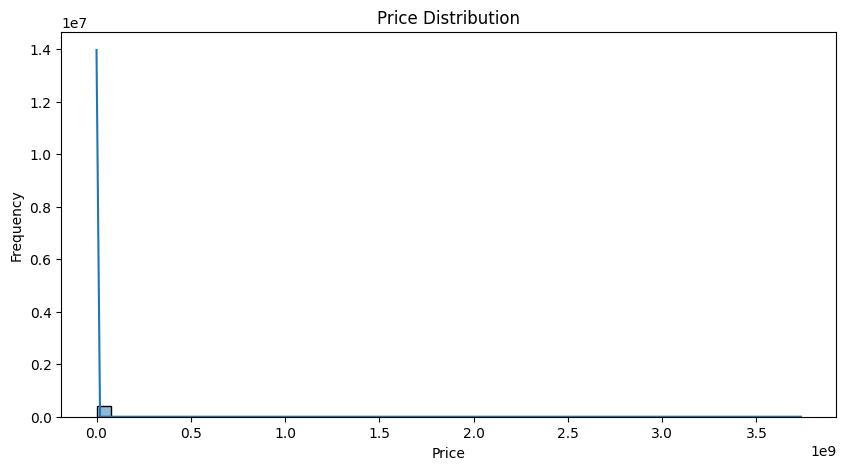

In [8]:
# Price distribution (target variable)
plt.figure(figsize=(10, 5))
sns.histplot(df['price'].dropna(), bins=50, edgecolor='black', kde=True)
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

## 3. Data Cleaning and Outlier Removal
We filter out unrealistic prices and mileage values, and use the Z-score method on the log-transformed price to remove extreme outliers.

In [9]:
before = len(df)

# 1. Remove impossible or placeholder prices (adjust bounds to taste)
df = df[(df['price'] >= 1000) & (df['price'] <= 200_000)]

# 2. Remove impossible mileage (keep NaN for now, it's dropped later)
df = df[df['odometer'].isna() | (df['odometer'] <= 500_000)]

# 3. Z-score on log price to catch remaining extremes
z = np.abs(stats.zscore(np.log1p(df['price'])))
df = df[z < 3].reset_index(drop=True)

print(f"Before: {before} rows | After: {len(df)} rows | Removed: {before - len(df)}")

Before: 426880 rows | After: 377943 rows | Removed: 48937


### 3.1. Re-plotting Price Distribution
Let's see how the price distribution looks after filtering extreme values.

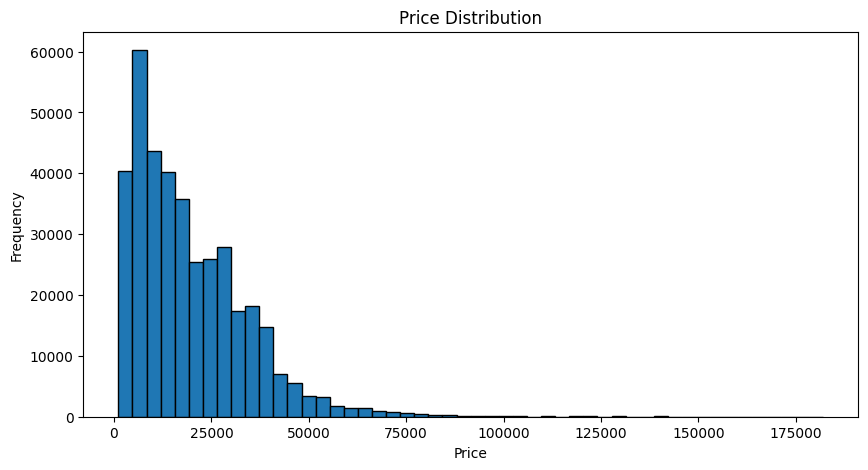

In [10]:
# Price distribution (target variable)
plt.figure(figsize=(10, 5))
plt.hist(df['price'].dropna(), bins=50, edgecolor='black')
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

### 3.2. Categorical Variable Distributions
We check the distributions of some core categorical columns: `condition`, `transmission`, and the numerical values `year`, `odometer`, and `manufacturer` count.

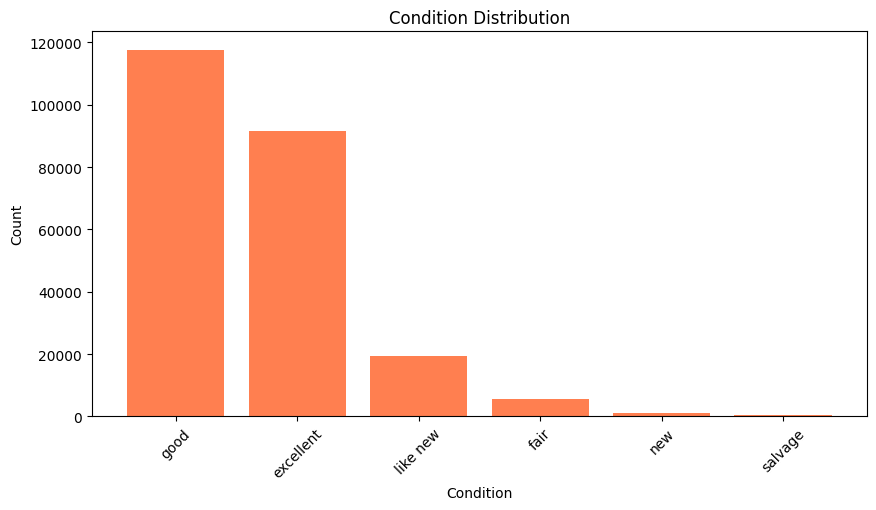

In [11]:
# Condition distribution
condition_counts = df['condition'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(condition_counts.index, condition_counts.values, color='coral')
plt.title('Condition Distribution')
plt.xlabel('Condition')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

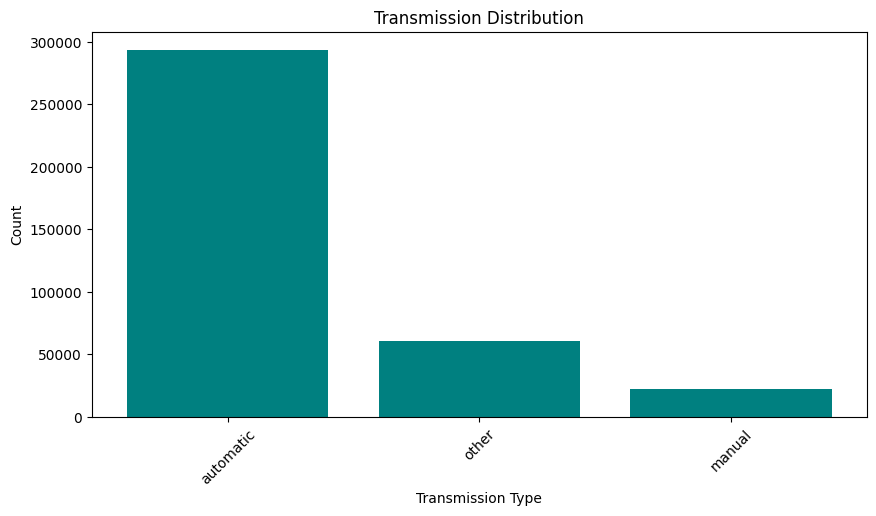

In [12]:
# Transmission distribution
transmission_counts = df['transmission'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(transmission_counts.index, transmission_counts.values, color='teal')
plt.title('Transmission Distribution')
plt.xlabel('Transmission Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

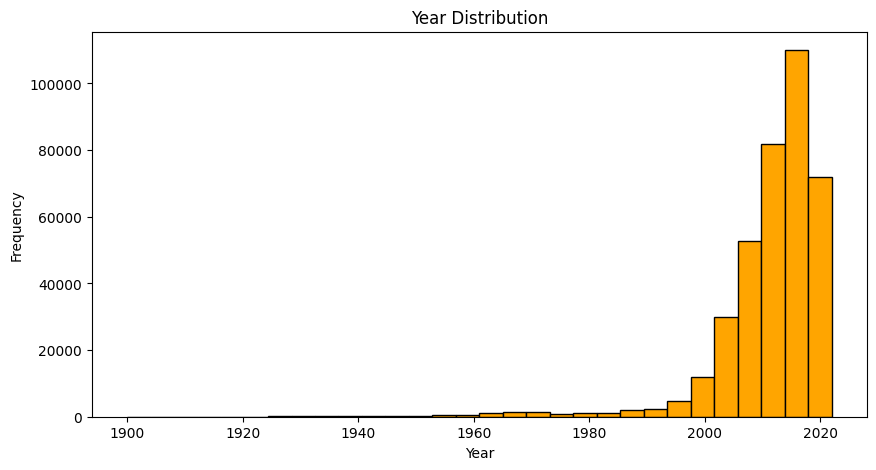

In [13]:
# Year distribution
plt.figure(figsize=(10, 5))
plt.hist(df['year'].dropna(), bins=30, edgecolor='black', color='orange')
plt.title('Year Distribution')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.show()

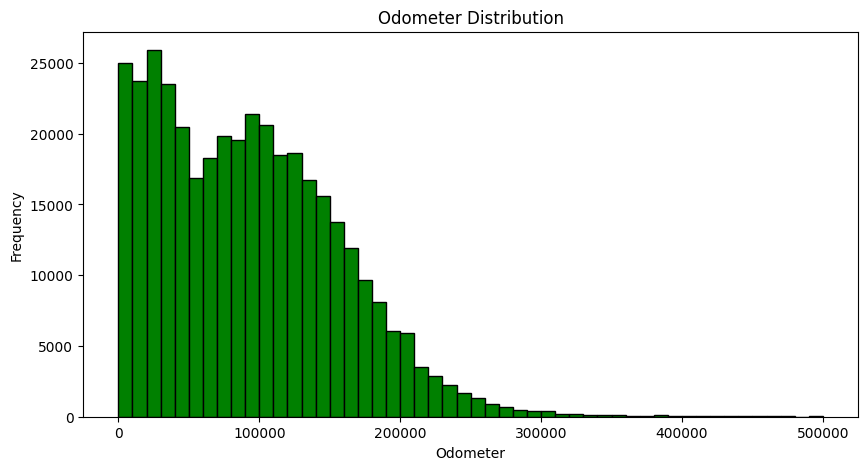

In [14]:
# Odometer distribution
plt.figure(figsize=(10, 5))
plt.hist(df['odometer'].dropna(), bins=50, edgecolor='black', color='green')
plt.title('Odometer Distribution')
plt.xlabel('Odometer')
plt.ylabel('Frequency')
plt.show()

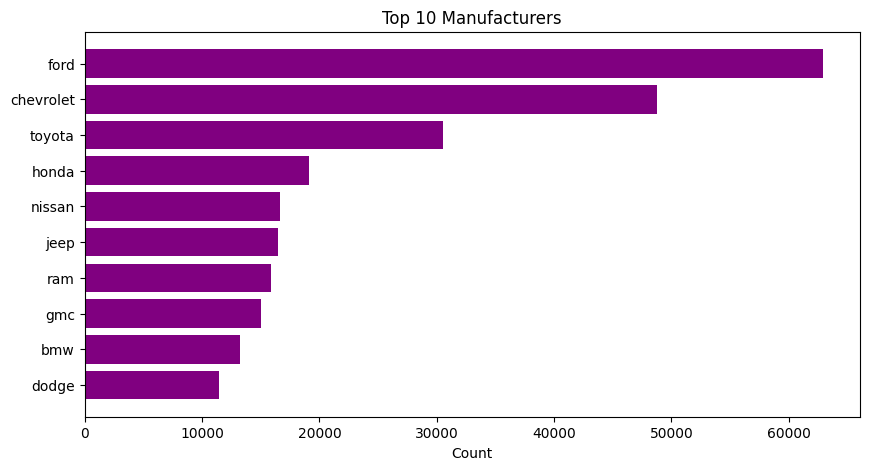

In [15]:
# Top manufacturers
top_manufacturers = df['manufacturer'].value_counts().head(10)
plt.figure(figsize=(10, 5))
plt.barh(top_manufacturers.index, top_manufacturers.values, color='purple')
plt.title('Top 10 Manufacturers')
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.show()

### 3.3. Outlier Analysis (IQR Method)
We identify and count the remaining outliers using the Interquartile Range (IQR) method.

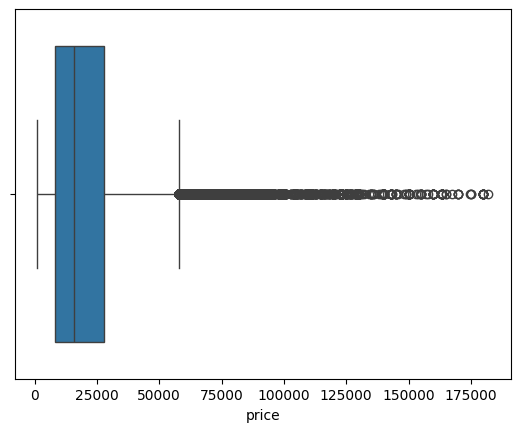

In [16]:
sns.boxplot(x=df['price'])
plt.show()

In [17]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

lower, upper

(np.float64(-21997.5), np.float64(57982.5))

In [18]:
outliers = df[(df["price"] < lower) | (df["price"] > upper)]

print("Number of outliers:", len(outliers))
print(outliers[["price"]])

Number of outliers: 7821
         price
191      58977
324      98900
341      72900
428      99950
668     100000
...        ...
377769   59900
377791   65950
377846   65995
377878   58995
377904   65999

[7821 rows x 1 columns]


### 3.3.1 Outlier Analysis Findings

The Interquartile Range (IQR) method was used to identify unusual vehicle prices.

After the initial filtering process, **7,821 price outliers** were identified using the IQR boundaries.

These observations were not automatically removed because unusually high prices may represent luxury, collectible, or specialty vehicles.

The IQR analysis helps identify extreme observations that may influence average prices and visualizations.

**Decision:** Retain the remaining IQR outliers for further analysis while acknowledging their potential influence on the results.

## 4. Feature Selection and Missing Value Imputation
We subset the most relevant columns for analysis, drop rows with critical missing numbers, and impute categorical nulls with `'unknown'` or the mode.

In [19]:
# Select relevant columns for car price analysis
cols = ['price', 'year', 'manufacturer', 'condition', 'cylinders', 'fuel', 'odometer', 'transmission', 'type']

df_clean = df[cols].copy()
print("Before:", df_clean.shape)

# Remove rows missing essential numerical values
df_clean = df_clean.dropna(subset=['price', 'year', 'odometer'])

print("After:", df_clean.shape)

Before: (377943, 9)
After: (374762, 9)


In [20]:
# Fill categorical columns with 'unknown' - missing likely means "not specified"
for col in ['manufacturer', 'condition', 'fuel', 'transmission', 'type']:
    df_clean[col] = df_clean[col].fillna('unknown')

# Fill cylinders with mode - discrete feature, mode is most representative
df_clean['cylinders'] = df_clean['cylinders'].fillna(df_clean['cylinders'].mode()[0])

print("Missing values remaining:", df_clean.isnull().sum())
print("Duplicate IDs:", df['id'].duplicated().sum())
print("Duplicate selected features:", df_clean.duplicated().sum())

Missing values remaining: price           0
year            0
manufacturer    0
condition       0
cylinders       0
fuel            0
odometer        0
transmission    0
type            0
dtype: int64
Duplicate IDs: 0
Duplicate selected features: 159494


In [21]:
# Convert manufacturing year to integer
df_clean['year'] = df_clean['year'].astype(int)

# Check updated data types
print(df_clean.dtypes)

price             int64
year              int64
manufacturer     object
condition        object
cylinders        object
fuel             object
odometer        float64
transmission     object
type             object
dtype: object


In [22]:
print("Invalid prices:", (df_clean['price'] <= 0).sum())
print("Invalid years:", (~df_clean['year'].between(1900, 2026)).sum())
print("Invalid odometer:", (df_clean['odometer'] < 0).sum())
print("Missing values:", df_clean.isnull().sum().sum())
print("Final shape:", df_clean.shape)

Invalid prices: 0
Invalid years: 0
Invalid odometer: 0
Missing values: 0
Final shape: (374762, 9)


### 4.1 Data Cleaning Summary

The dataset was cleaned to improve its quality and suitability for analysis.

**Cleaning steps performed:**
- Removed the completely empty `county` column.
- Checked for duplicate records.
- Filtered prices outside the selected range of $1,000–$200,000.
- Excluded mileage values above 500,000.
- Applied Z-score filtering to log-transformed prices.
- Removed rows missing essential numerical values.
- Replaced missing categorical values with `unknown`.
- Filled missing cylinder values using the mode.
- Converted manufacturing year to an integer.

**Cleaning Results:**

| Metric | Result |
|---|---:|
| Original records | 426,880 |
| Records after initial filtering | 377,943 |
| Final records | 374,762 |
| Selected features | 9 |
| Remaining missing values | 0 |
| Invalid values in final validation | 0 |

**Duplicate Analysis:**

No duplicate listing IDs were found. However, 159,494 rows share identical values across the selected nine features. These were retained because identical characteristics do not necessarily indicate duplicate vehicle listings.

**Note:** The selected price and mileage limits are analytical assumptions and may exclude some legitimate listings.

In [23]:
df_clean.to_csv("clean_data.csv", index=False)

print("Dataset saved successfully!")
print("Final shape:", df_clean.shape)

Dataset saved successfully!
Final shape: (374762, 9)


### 4.2. Feature Correlation
We plot a heatmap of the numerical features to find linear relationships.

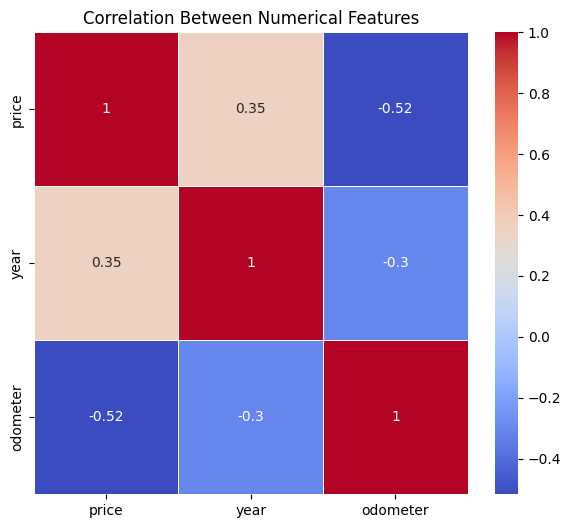

In [24]:
numeric_cols = ['price', 'year', 'odometer']
corr = df_clean[numeric_cols].corr()
plt.figure(figsize=(7,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", linewidths=0.5)

plt.title("Correlation Between Numerical Features")
plt.show()

## 5. Exploratory Data Visualization
We construct plots to explore relationships between pricing and attributes such as the production year, odometer reading, and top manufacturers.

### 5.1 Price vs Manufacturing Year

**Objective:** Examine the relationship between manufacturing year and vehicle listing price.

A scatter plot is used to visualize how prices vary across different manufacturing years.

**Questions to investigate:**
- Do newer vehicles generally have higher listing prices?
- Are older vehicles consistently less expensive?
- Are there unusual prices among older or newer vehicles?

**Method:** A random sample of 10,000 records is used to improve visualization performance.

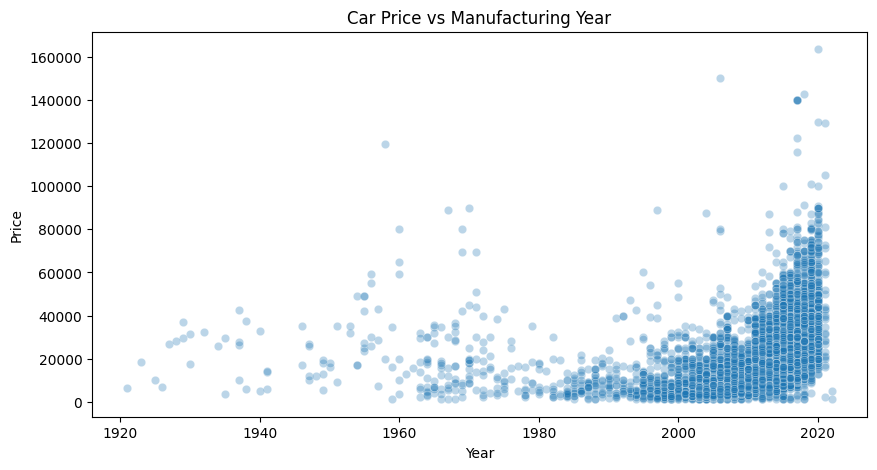

In [25]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_clean.sample(n=10000, random_state=42), x='year', y='price', alpha=0.3)
plt.title("Car Price vs Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Price")
plt.show()

### 5.2 Price vs Odometer

**Objective:** Investigate the relationship between vehicle mileage and listing price.

The scatter plot compares odometer readings with vehicle prices to explore whether higher mileage is associated with lower prices.

**Questions to investigate:**
- Is there a negative relationship between mileage and price?
- How much variation exists among vehicles with similar mileage?
- Are there expensive vehicles with unusually high mileage?

**Method:** A random sample of 10,000 records is used for visualization.

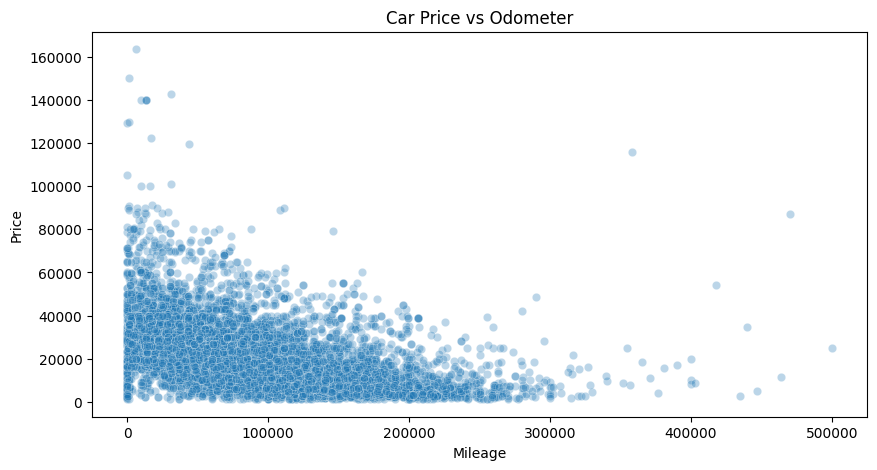

In [26]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_clean.sample(n=10000, random_state=42), x='odometer', y='price', alpha=0.3)
plt.title("Car Price vs Odometer")
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.show()

### 5.3 Average Price by Manufacturer

**Objective:** Compare average vehicle listing prices across manufacturers.

The bar chart displays the ten manufacturers with the highest average listing prices.

**Questions to investigate:**
- Which manufacturers have the highest average prices?
- How large are the price differences between manufacturers?
- Could differences in vehicle age, type, or listing counts influence the results?

**Limitation:** Average prices can be affected by extreme values and unequal sample sizes across manufacturers.

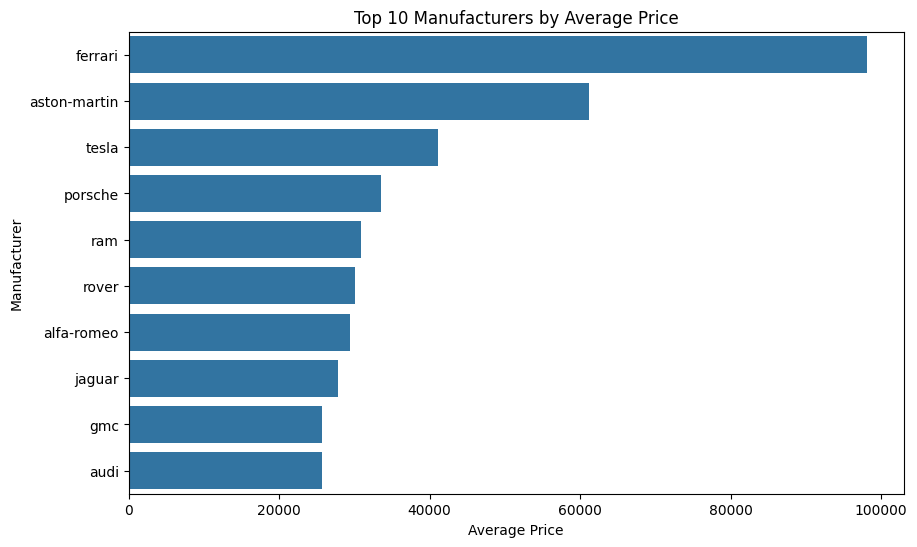

In [27]:
avg_price = (df_clean.groupby('manufacturer')['price'].mean().sort_values(ascending=False).head(10))
plt.figure(figsize=(10, 6))
sns.barplot( x=avg_price.values, y=avg_price.index)
plt.title("Top 10 Manufacturers by Average Price")
plt.xlabel("Average Price")
plt.ylabel("Manufacturer")
plt.show()

In [28]:
print("Correlation with price:")
print(df_clean[['price', 'year', 'odometer']].corr()['price'])

print("\nTop manufacturers by average price:")
print(df_clean.groupby('manufacturer')['price'].mean().sort_values(ascending=False).head(10))

Correlation with price:
price       1.000000
year        0.353174
odometer   -0.517131
Name: price, dtype: float64

Top manufacturers by average price:
manufacturer
ferrari         98108.093750
aston-martin    61136.619048
tesla           41123.519159
porsche         33510.325619
ram             30919.182870
rover           30140.602544
alfa-romeo      29481.951878
jaguar          27796.347147
gmc             25647.685236
audi            25638.392126
Name: price, dtype: float64


## 6. Key Insights and Findings

### 6.1 Car Price and Manufacturing Year

The correlation between manufacturing year and car price is **0.353**, indicating a moderate positive relationship. This suggests that newer vehicles generally tend to have higher listing prices, although other factors also influence pricing.

### 6.2 Car Price and Mileage

The correlation between mileage and car price is **-0.517**, indicating a moderate negative relationship. This suggests that vehicles with higher mileage generally tend to have lower listing prices.

Mileage shows a stronger linear relationship with price than manufacturing year in this dataset.

### 6.3 Average Price by Manufacturer

The analysis shows that **Ferrari** has the highest average listing price at approximately **$98,108**, followed by **Aston Martin ($61,137)** and **Tesla ($41,124)**.

These results highlight differences in average listing prices between manufacturers. However, the comparison may be affected by vehicle type, age, condition, and the number of listings for each manufacturer.

### 6.4 Data Cleaning and Outliers

Data cleaning was performed to improve the quality and consistency of the dataset.

**Cleaning Results:**

| Metric | Result |
|---|---:|
| Original records | 426,880 |
| Final records | 374,762 |
| Removed records | 52,118 |
| Selected features | 9 |
| Remaining missing values | 0 |
| Invalid values in final checks | 0 |

The cleaning process included:

- Removing records with prices outside the selected range.
- Filtering unusually high mileage values.
- Handling missing numerical and categorical values.
- Checking duplicate records and feature combinations.
- Converting manufacturing year to an integer.
- Identifying remaining price outliers using the IQR method.

Some unusual observations were retained because they may represent legitimate vehicle listings.

### 6.5 Key Takeaways

- Manufacturing year, mileage, and manufacturer are useful variables for exploring used car listing prices.
- Data cleaning reduced the dataset from 426,880 to 374,762 records.
- Scatter plots and correlation analysis help examine relationships between numerical variables.
- Manufacturer comparisons help explore differences in average listing prices.
- Outlier analysis is important because extreme prices may influence summary statistics.
- The cleaned dataset provides a foundation for building an interactive Streamlit dashboard.

## 7. Conclusion

### 7.1 Project Summary

In this project, we explored the Craigslist Used Car dataset to better understand vehicle prices and characteristics.

We started with 426,880 records and cleaned the dataset by handling missing values, checking duplicates, and filtering invalid or extreme values. After cleaning, we obtained 374,762 records with 9 selected features.

We used different visualizations, including histograms, boxplots, scatter plots, bar charts, and a correlation heatmap, to explore the data and examine relationships between vehicle prices, manufacturing year, mileage, and manufacturer.

### 7.2 Dataset Limitations

The dataset has some limitations:

- Some records contained missing or unusual values.
- Listed prices may differ from actual selling prices.
- Filtering extreme values may remove some valid vehicle listings.
- Other factors, such as vehicle history and location, may also affect prices.

### 7.3 Future Improvements

In the future, this analysis could be improved by:

- Exploring additional features such as vehicle condition, fuel type, and location.
- Comparing vehicle prices across different regions.
- Building an interactive Streamlit dashboard to explore the data using filters.
- Adding more visualizations to understand pricing patterns.

### 7.4 Final Conclusion

This project helped us practice data cleaning, exploratory data analysis, and data visualization using Python.

The analysis provides a foundation for understanding used car listing prices and shows how data analysis can help identify patterns and support better decisions.